# Lab 1 – podstawowa analiza obrazu

W tym ćwiczeniu samodzielnie przeprowadzisz podstawową analizę obrazu cyfrowego z wykorzystaniem biblioteki `scikit-image`.

Twoim celem jest przejście przez cały prosty proces analizy:

**wczytanie obrazu → sprawdzenie jego właściwości → analiza kanałów → skala szarości → histogram → normalizacja → wyrównanie histogramu**


In [2]:
# ============================================
# Import potrzebnych bibliotek
# ============================================
import numpy as np                          # NumPy – obsługa tablic i obliczeń numerycznych
import matplotlib.pyplot as plt              # Matplotlib – do rysowania i wyświetlania obrazów
from skimage import io, color, exposure, filters, util, morphology
# skimage.io          – wczytywanie/zapisywanie obrazów
# skimage.color       – konwersja przestrzeni barw (np. RGB → grayscale)
# skimage.exposure    – regulacja jasności, kontrastu, histogramów itp.
# skimage.filters     – filtry obrazu (np. rozmycie, wykrywanie krawędzi)
# skimage.util        – operacje pomocnicze (np. dodawanie szumu)
# skimage.morphology  – operacje morfologiczne (np. erozja, dylatacja)
from skimage.metrics import structural_similarity as ssim
# skimage.metrics.ssim – metryka podobieństwa strukturalnego (ocena podobieństwa obrazów)

# ============================================
# Ustawienia wykresów
# ============================================
plt.rcParams["figure.figsize"] = (12, 4)     # Domyślny rozmiar rysunku: szerokość 12 cali, wysokość 4 cale

## 1. Wybierz obraz

Wybierz jeden obraz z wbudowanej bazy:

```python
skimage.data
```

Możesz wykorzystać np.:

```python
data.camera()
data.coins()
data.chelsea()
data.coffee()
data.horse()
data.moon()
data.rocket()
```

Nie wybieraj obrazu `astronaut`, ponieważ był już analizowany podczas zajęć.

Wyświetl wybrany obraz.


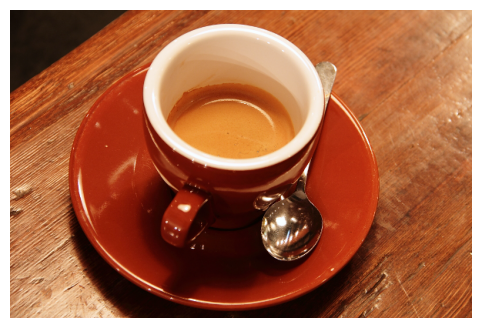

In [3]:
from skimage import data, color, exposure, img_as_float
import numpy as np
import matplotlib.pyplot as plt

# Wczytaj wybrany obraz
img = data.coffee()

# Wyświetl obraz
fig, ax = plt.subplots()

ax.imshow(img)
ax.axis("off")

plt.show()

## 2. Sprawdź podstawowe informacje o obrazie

Sprawdź:

```python
img.shape
img.dtype
img.min()
img.max()
```

Zwróć uwagę na:

- wymiary obrazu,
- liczbę kanałów,
- typ danych,
- minimalną i maksymalną wartość pikseli.

### Zastanów się

Co informacje zwracane przez `shape` mówią o obrazie?  
Czy wartości pikseli są zapisane w zakresie `0–255`, czy `0–1`?


In [4]:
height, width, channels = img.shape
print("Wymiary obrazu:", (width, height))
print("Kanały:", channels)
print("Typ danych:", img.dtype)
# Wartości zapisane w 0-255
print("Minimalna wartość:", img.min())
print("Maksymalna wartość:", img.max())

Wymiary obrazu: (600, 400)
Kanały: 3
Typ danych: uint8
Minimalna wartość: 0
Maksymalna wartość: 255


## 3. Określ rodzaj obrazu

Na podstawie wymiarów określ, czy obraz jest:

- obrazem w skali szarości,
- obrazem RGB,
- obrazem RGBA.

Przykładowo:

```text
(wysokość, szerokość)
```

oznacza zazwyczaj obraz w skali szarości,

natomiast:

```text
(wysokość, szerokość, 3)
```

oznacza obraz RGB.


In [5]:
from PIL import Image

pil_img = Image.fromarray(img)

pil_img.getbands()

('R', 'G', 'B')

## 4. Przeanalizuj kanały obrazu

Jeżeli wybrany obraz jest obrazem RGB, wydziel jego trzy kanały:

- R – czerwony,
- G – zielony,
- B – niebieski.

Wyświetl obok siebie:

**obraz RGB | kanał R | kanał G | kanał B**

Kanały możesz wyświetlić w skali szarości, ponieważ wtedy jasność piksela pokazuje intensywność danego kanału.

### Zastanów się

W których fragmentach obrazu poszczególne kanały są najjaśniejsze?  
Czy da się powiązać to z kolorami widocznymi na obrazie oryginalnym?

Jeśli obraz jest już w skali szarości, pomiń ten etap.


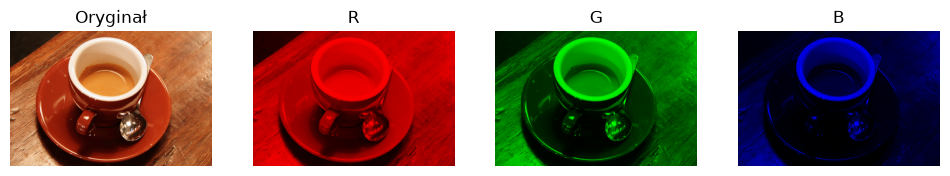

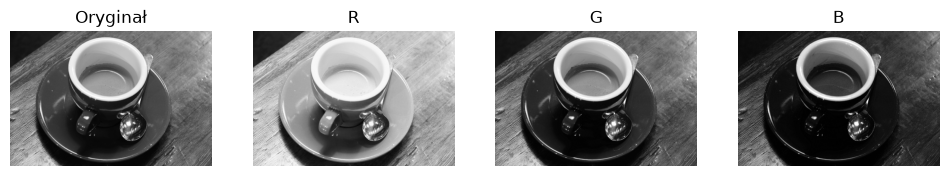

In [6]:
# Jeśli obraz jest RGB, wyświetl jego kanały R, G i B
def show_row(images, titles=None, cmap=None):
    """
    Wyświetla kilka obrazów obok siebie w jednym wierszu.

    Parametry:
    -----------
    images : list
        Lista obrazów (tablic NumPy) do wyświetlenia.
    titles : list (opcjonalnie)
        Lista tytułów dla każdego obrazu.
    cmap : str (opcjonalnie)
        Mapa kolorów (np. 'gray' dla obrazów w skali szarości).
    """

    n = len(images)                          # Liczba obrazów
    fig, axes = plt.subplots(1, n)           # Tworzy jeden wiersz z n kolumnami (dla każdego obrazu jedna oś)

    # Iteracja po wszystkich obrazach i ich osiach
    for i, ax in enumerate(np.atleast_1d(axes)):
        ax.imshow(images[i], cmap=cmap)      # Wyświetla obraz (z opcjonalną mapą kolorów)
        ax.axis('off')                       # Ukrywa osie (ramki, skale, liczby)
        if titles:                           # Jeśli podano tytuły
            ax.set_title(titles[i])          # Ustawia tytuł nad obrazem

    plt.show()                               # Wyświetla całość

# Kanał czerwony
red = np.zeros_like(img)
red[:, :, 0] = img[:, :, 0]

# Kanał zielony
green = np.zeros_like(img)
green[:, :, 1] = img[:, :, 1]

# Kanał niebieski
blue = np.zeros_like(img)
blue[:, :, 2] = img[:, :, 2]

show_row([img, red, green, blue], ["Oryginał", "R", "G", "B"])

show_row(list(map(lambda x: color.rgb2gray(x), [img, red, green, blue])), ["Oryginał", "R", "G", "B"], cmap="gray")

## 5. Przekonwertuj obraz do skali szarości

Jeżeli obraz jest kolorowy, przekonwertuj go do skali szarości:

```python
gray = color.rgb2gray(img)
```

Wyświetl obraz przed i po konwersji.

Ponownie sprawdź:

```python
gray.shape
gray.dtype
gray.min()
gray.max()
```

### Zastanów się

Co zmieniło się w strukturze danych po usunięciu informacji o kolorze?


In [7]:
# Utwórz obraz w skali szarości
# Zniknęły kanały i wartości jasności zostały przeskalowane do 0-1

gray = color.rgb2gray(img)

height, width = gray.shape
print("Wymiary obrazu:", (width, height))
print("Typ danych:", gray.dtype)
# Wartości zapisane w 0-1
print("Minimalna wartość:", gray.min())
print("Maksymalna wartość:", gray.max())

Wymiary obrazu: (600, 400)
Typ danych: float64
Minimalna wartość: 0.0002827450980392157
Maksymalna wartość: 1.0


## 6. Narysuj histogram jasności

Dla obrazu w skali szarości utwórz histogram.

Użyj:

```python
bins=256
```

Pamiętaj, aby zakres histogramu odpowiadał zakresowi wartości pikseli.

Dla obrazu w zakresie `0–1`:

```python
range=(0, 1)
```

Dla obrazu w zakresie `0–255`:

```python
range=(0, 255)
```

Podpisz osie:

- oś X – poziom jasności,
- oś Y – liczba pikseli.

### Zastanów się

Czy większość pikseli znajduje się w obszarze ciemnych, średnich czy jasnych wartości?  
Czy histogram wykorzystuje szeroki zakres intensywności, czy wartości są skupione w niewielkim obszarze?


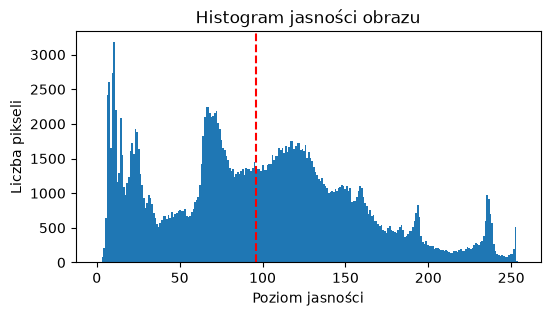

In [15]:
# Narysuj histogram obrazu w skali szarości
def draw_hist(image, bins, range):
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.hist(image.ravel(), bins=bins, range=range)

    ax.axvline(np.median(image.ravel()), color="red", linestyle="dashed")

    plt.title("Histogram jasności obrazu")
    plt.xlabel("Poziom jasności")
    plt.ylabel("Liczba pikseli")

    plt.show()

gray_8bit = (gray * 255).astype(np.uint8)

draw_hist(gray_8bit, 256, range=(0, 255))

## 7. Wykonaj normalizację

Wykonaj normalizację obrazu za pomocą:

```python
exposure.rescale_intensity()
```

Przeskaluj wartości pikseli do zakresu:

```text
0–1
```

Wyświetl:

**obraz przed normalizacją | obraz po normalizacji**

Narysuj również histogramy obu obrazów.

### Zastanów się

Czy zakres wartości został rozciągnięty?  
Czy kontrast obrazu zmienił się zauważalnie?  
Jeżeli zmiana jest niewielka, spróbuj wyjaśnić, z czego może to wynikać.


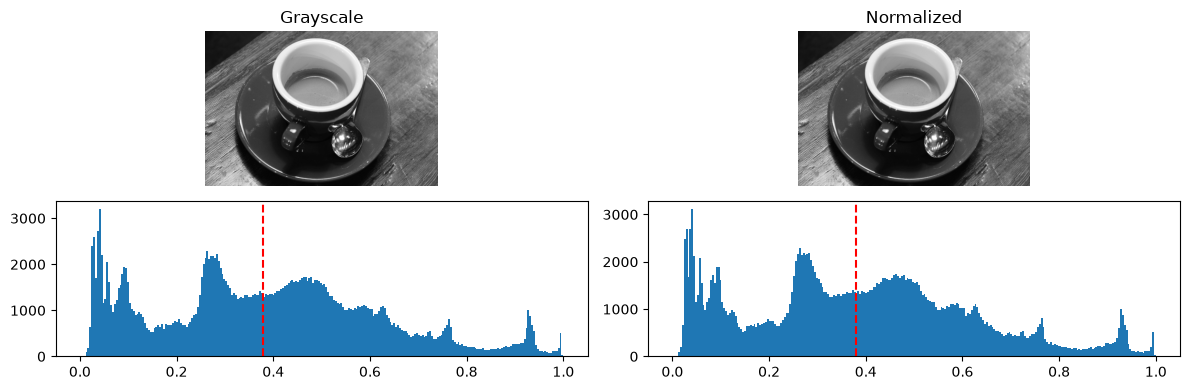

In [ ]:
# Wykonaj normalizację i porównaj obraz przed i po normalizacji
norm = exposure.rescale_intensity(
    gray,
    in_range='image',
    out_range=(0, 1)
)

fig, axes = plt.subplots(2, 2)

axes[0, 0].imshow(gray, cmap="gray")
axes[0, 0].set_title("Grayscale")
axes[0, 0].axis("off")

axes[0, 1].imshow(norm, cmap="gray")
axes[0, 1].set_title("Normalized")
axes[0, 1].axis("off")

axes[1, 0].hist(gray.ravel(), bins=256, range=(0, 1))
axes[1, 0].axvline(np.median(gray.ravel()), color="red", linestyle="dashed")

axes[1, 1].hist(norm.ravel(), bins=256, range=(0, 1))
axes[1, 1].axvline(np.median(norm.ravel()), color="red", linestyle="dashed")

plt.tight_layout()
plt.show()

# Praktycznie nie ma zmiany, bo obraz już na starcie był w pełnym zakresie

## 8. Wykonaj wyrównanie histogramu

Wykonaj wyrównanie histogramu:

```python
exposure.equalize_hist()
```

Wyświetl:

**obraz przed wyrównaniem | obraz po wyrównaniu**

Narysuj histogram obrazu wynikowego.

### Zastanów się

Jak zmienił się rozkład poziomów jasności?  
Czy szczegóły obrazu stały się bardziej widoczne?  
Czy histogram jest bardziej rozłożony w całym dostępnym zakresie?


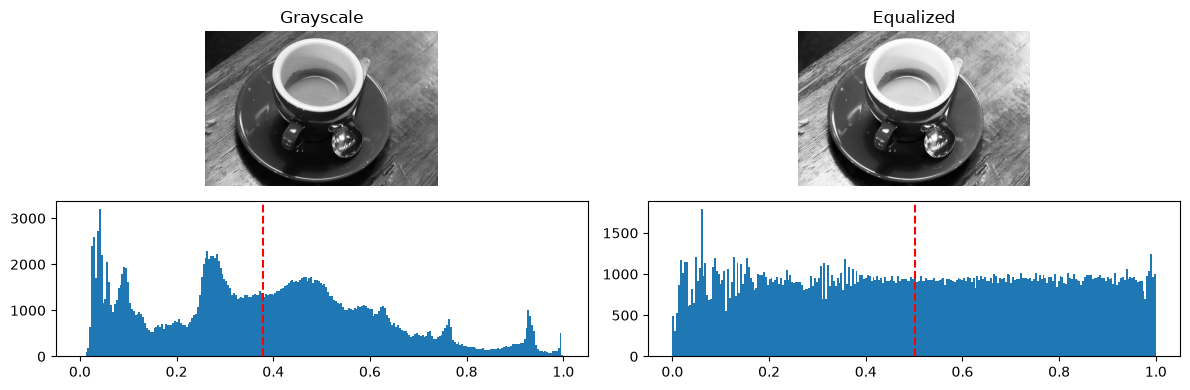

In [22]:
# Wykonaj wyrównanie histogramu i wyświetl wynik
eq = exposure.equalize_hist(gray)

fig, axes = plt.subplots(2, 2)

axes[0, 0].imshow(gray, cmap="gray")
axes[0, 0].set_title("Grayscale")
axes[0, 0].axis("off")

axes[0, 1].imshow(eq, cmap="gray")
axes[0, 1].set_title("Equalized")
axes[0, 1].axis("off")

axes[1, 0].hist(gray.ravel(), bins=256, range=(0, 1))
axes[1, 0].axvline(np.median(gray.ravel()), color="red", linestyle="dashed")

axes[1, 1].hist(eq.ravel(), bins=256, range=(0, 1))
axes[1, 1].axvline(np.median(eq.ravel()), color="red", linestyle="dashed")

plt.tight_layout()
plt.show()

## 9. Porównaj wyniki

Na jednej figurze wyświetl:

```text
Oryginał | Normalizacja | Wyrównanie histogramu
```

Poniżej umieść odpowiadające im histogramy.

Porównaj wygląd obrazów i rozkład intensywności.

### Zastanów się nad różnicą pomiędzy normalizacją i wyrównaniem histogramu

Normalizacja przede wszystkim rozciąga zakres wartości, natomiast wyrównanie histogramu zmienia sposób rozmieszczenia intensywności w tym zakresie.


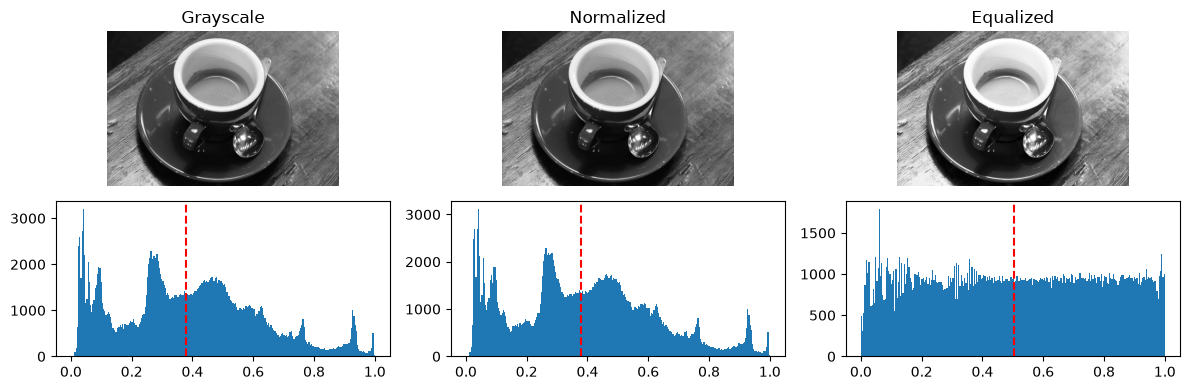

In [25]:
# Porównaj obraz oryginalny, po normalizacji i po wyrównaniu histogramu

fig, axes = plt.subplots(2, 3)

axes[0, 0].imshow(gray, cmap="gray")
axes[0, 0].set_title("Grayscale")
axes[0, 0].axis("off")

axes[0, 1].imshow(norm, cmap="gray")
axes[0, 1].set_title("Normalized")
axes[0, 1].axis("off")

axes[0, 2].imshow(eq, cmap="gray")
axes[0, 2].set_title("Equalized")
axes[0, 2].axis("off")

axes[1, 0].hist(gray.ravel(), bins=256, range=(0, 1))
axes[1, 0].axvline(np.median(gray.ravel()), color="red", linestyle="dashed")

axes[1, 1].hist(norm.ravel(), bins=256, range=(0, 1))
axes[1, 1].axvline(np.median(norm.ravel()), color="red", linestyle="dashed")

axes[1, 2].hist(eq.ravel(), bins=256, range=(0, 1))
axes[1, 2].axvline(np.median(eq.ravel()), color="red", linestyle="dashed")

plt.tight_layout()
plt.show()

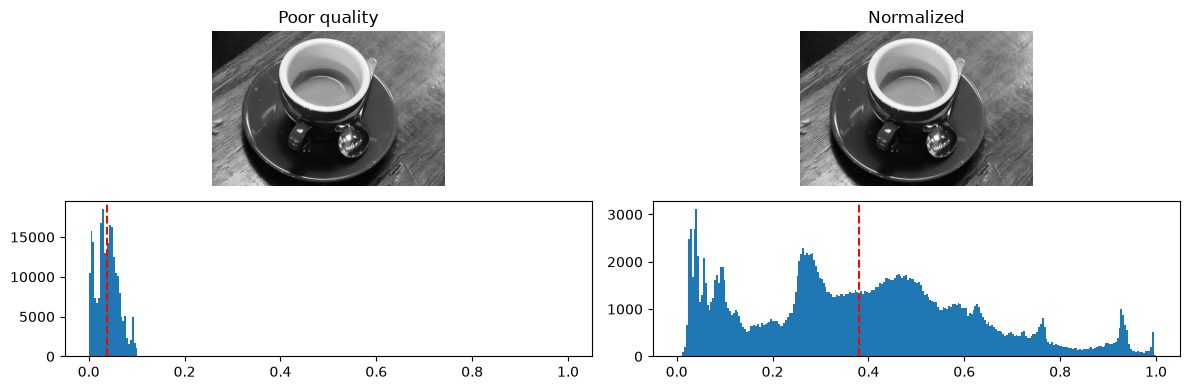

In [34]:
# Extra. Zły obraz

poor = exposure.rescale_intensity(gray, out_range=(0, 0.1))

fig, axes = plt.subplots(2, 2)

axes[0, 0].imshow(poor, cmap="gray")
axes[0, 0].set_title("Poor quality")
axes[0, 0].axis("off")

axes[0, 1].imshow(norm, cmap="gray")
axes[0, 1].set_title("Normalized")
axes[0, 1].axis("off")

axes[1, 0].hist(poor.ravel(), bins=256, range=(0, 1))
axes[1, 0].axvline(np.median(poor.ravel()), color="red", linestyle="dashed")

axes[1, 1].hist(norm.ravel(), bins=256, range=(0, 1))
axes[1, 1].axvline(np.median(norm.ravel()), color="red", linestyle="dashed")

plt.tight_layout()
plt.show()